In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/semantic_ablation/source_snapshot.csv').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})


# 06 · Final context optimization benchmark

## tl;dr
Use validation mean F1 to select the global 128-row strategy and the 512-row semantic representation separately. Compare each winner with its matched baseline on the untouched holdout. Do not merge the two interventions into a new claim without a combined validation experiment.

## Methods
Five seeds for global selection and three for semantic validation. The final holdout has 128 rows and eight fraud positives. Selection validation uses rows 897–1024; final holdout labels never choose a winner. Relative improvement is undefined when baseline F1 is zero, so report absolute change. Semantic comparisons use a different 512-row budget and are shown separately.

In [2]:
validation=pd.read_csv(ROOT/'data/context_benchmark/selection_validation_results.csv')
selection=pd.read_csv(ROOT/'data/context_benchmark/selection_holdout_results.csv')
size=pd.read_csv(ROOT/'data/context_benchmark/size_results.csv')
chosen={k:v[1] for k,v in validation.groupby(['target','strategy']).f1.mean().groupby(level=0).idxmax().items()}
rows=[]
for target in ['paid_late','is_fraud']:
    for label,frame in [('XGBoost, 128',size[(size.model=='XGBoost')&(size['size']==128)]),('SAP RPT, random',selection[selection.strategy=='random']),('SAP RPT, validated',selection[selection.strategy==chosen[target]])]:
        sub=frame[frame.target==target]; rows.append({'target':target,'configuration':label,'F1 mean':sub.f1.mean(),'F1 SD':sub.f1.std(),'recall mean':sub.recall.mean(),'false positives mean':sub.false_positives.mean(),'inference seconds mean':sub.inference_seconds.mean()})
summary=pd.DataFrame(rows); display(summary.round(3))

,target,configuration,F1 mean,F1 SD,recall mean,false positives mean,inference seconds mean
0,paid_late,"XGBoost, 128",0.564,0.017,0.647,33.0,0.001
1,paid_late,"SAP RPT, random",0.544,0.031,0.557,24.6,0.395
2,paid_late,"SAP RPT, validated",0.558,0.060,0.616,30.0,0.424
3,is_fraud,"XGBoost, 128",0.059,0.081,0.050,4.6,0.001
4,is_fraud,"SAP RPT, random",0.000,0.000,0.000,0.0,0.398
5,is_fraud,"SAP RPT, validated",0.388,0.018,0.750,17.0,0.665


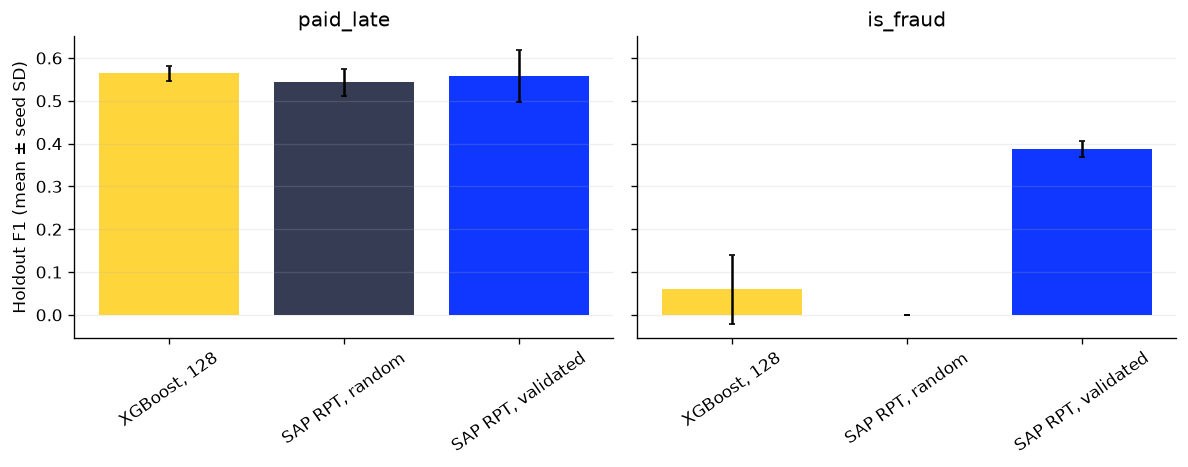

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4),sharey=True)
for ax,target in zip(axes,['paid_late','is_fraud']):
    sub=summary[summary.target==target]; ax.bar(sub.configuration,sub['F1 mean'],yerr=sub['F1 SD'],capsize=2,color=['#FFD53C','#353C54','#0F37FF']); ax.tick_params(axis='x',rotation=35); ax.set_title(target); ax.grid(axis='y',alpha=.2)
axes[0].set_ylabel('Holdout F1 (mean ± seed SD)'); plt.tight_layout(); plt.show()

In [4]:
sem_val=pd.read_csv(ROOT/'data/semantic_ablation/validation_results.csv')
sem_final=pd.read_csv(ROOT/'data/semantic_ablation/results.csv')
semantic_choice={target: sub.groupby('condition').f1.mean().idxmax() for target,sub in sem_val.groupby('target')}
print('Validation-selected semantic representation:',semantic_choice)
semantic_summary=sem_final[(sem_final.model=='SAP-RPT') & (sem_final.condition.isin(['S0',*semantic_choice.values()]))].groupby(['target','condition'])[['f1','recall']].agg(['mean','std'])
display(semantic_summary.round(3))

Validation-selected semantic representation: {'is_fraud': 'S0', 'paid_late': 'S3'}


f1        recall       
                      mean    std   mean    std
target    condition                            
is_fraud  S0         0.000  0.000  0.000  0.000
          S3         0.000  0.000  0.000  0.000
paid_late S0         0.592  0.004  0.601  0.011
          S3         0.570  0.011  0.575  0.011

In [5]:
pred=pd.read_csv(ROOT/'data/context_benchmark/selection_holdout_predictions.csv')
for target in ['paid_late','is_fraud']:
    for strategy in ['random',chosen[target]]:
        run=f'selection_holdout|holdout|{strategy}|128|11|{target}|0|SAP-RPT'
        sub=pred[pred.run_id==run]
        errors=sub[sub.actual!=sub.predicted]
        print(target,strategy,'seed 11 errors',len(errors),'false negatives',((errors.actual==1)&(errors.predicted==0)).sum(),'false positives',((errors.actual==0)&(errors.predicted==1)).sum())

paid_late random seed 11 errors 44 false negatives 28 false positives 16
paid_late balanced seed 11 errors 51 false negatives 25 false positives 26
is_fraud random seed 11 errors 8 false negatives 8 false positives 0
is_fraud balanced seed 11 errors 20 false negatives 2 false positives 18


## Takeaways
Class-balanced context was selected on validation for both targets, with more fraud recall and many more false alarms on holdout. Validation selected S3 semantics for late payment, but its paired holdout F1 was lower than S0; all semantic variants tied for fraud on validation and S0 was retained. A combined balanced-plus-semantic condition was not validated, so this notebook makes no interaction claim for that combination. This is one synthetic dataset and one deployment, not a general model ranking.